In [2]:
import pandas as pd
import os

# This tells Python to look in the EXACT same folder as this notebook
current_dir = os.path.dirname(os.path.abspath('__file__'))
file_path = os.path.join(current_dir, 'data_v2.csv')

# The final attempt
df = pd.read_csv('data_v2.csv') 
print("Success! Dataset Shape:", df.shape)

Success! Dataset Shape: (284807, 31)


In [3]:
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split

# 1. Prepare features and target
X = df.drop('Class', axis=1)
y = df['Class']

# 2. Split BEFORE SMOTE (to prevent data leakage)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 3. Apply SMOTE to the TRAINING data only
smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

print(f"Original fraud cases: {sum(y_train == 1)}")
print(f"Post-SMOTE fraud cases: {sum(y_train_res == 1)}")

Original fraud cases: 394
Post-SMOTE fraud cases: 227451


In [4]:
from xgboost import XGBClassifier

# Initialize and train
aml_model = XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42)
aml_model.fit(X_train_res, y_train_res)

print("Advanced ML Model (XGBoost + SMOTE) Training Complete.")

C:\Users\reven\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\xgboost\training.py:200: UserWarning: [12:14:11] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Advanced ML Model (XGBoost + SMOTE) Training Complete.


--- PHASE 2: AML RESULTS ---
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.79      0.85      0.82        98

    accuracy                           1.00     56962
   macro avg       0.90      0.92      0.91     56962
weighted avg       1.00      1.00      1.00     56962



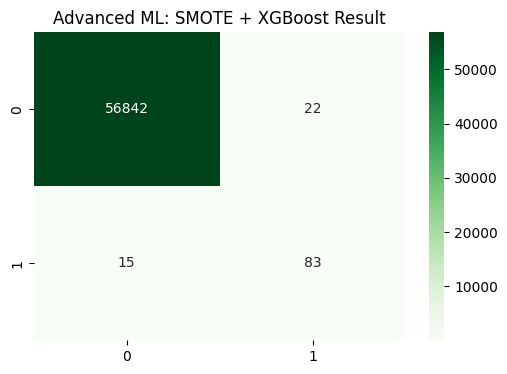

In [5]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

y_pred = aml_model.predict(X_test)

print("--- PHASE 2: AML RESULTS ---")
print(classification_report(y_test, y_pred))

# Confusion Matrix
plt.figure(figsize=(6,4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Greens')
plt.title('Advanced ML: SMOTE + XGBoost Result')
plt.show()

In [6]:
import joblib
joblib.dump(aml_model, '../../models/xgboost_smote_model.joblib')

['../../models/xgboost_smote_model.joblib']